##Simple FAQ AI Agent – Build an AI agent that answers user questions using a predefined FAQ knowledge base and returns the most relevant response.

##Project Architecture

User Selects Domain

        ↓
CSV Dataset Loaded

        ↓

Sentence Embeddings Generated

        ↓


User Asks Question

        ↓

Question Converted Into Embedding

        ↓

Cosine Similarity Calculation

        ↓

Best FAQ Match Selected

        ↓

Confidence Score Calculated

        ↓

Answer Returned

        ↓

Chat History Stored


In [1]:
!pip install sentence-transformers pandas colorama

In [2]:
import pandas as pd
from sentence_transformers import SentenceTransformer, util
from colorama import Fore, Style
from datetime import datetime

In [3]:
faq_domains = {

    "college": [
        {
        "question": "How can I apply for admission?",
        "answer": "You can apply through the online admission portal."
    },

    {
        "question": "Where is the computer lab located?",
        "answer": "The computer lab is located in Block C."
    },

    {
        "question": "How do I check my attendance?",
        "answer": "Attendance can be checked through the student portal."
    },

    {
        "question": "What are the college timings?",
        "answer": "College timings are from 9 AM to 5 PM."
    },

    {
        "question": "How can I access the library?",
        "answer": "Use your student ID card to access the library."
    },

    {
        "question": "Where can I see exam schedules?",
        "answer": "Exam schedules are available on the college notice board and website."
    },
        {
            "question": "How can I pay college fees?",
            "answer": "You can pay fees through the student portal."
        },
        {
            "question": "Where is the library located?",
            "answer": "The library is located in Block B."
        },
        {
            "question": "How do I check exam results?",
            "answer": "Exam results are available on the college website."
        },
        {
            "question": "What are college timings?",
            "answer": "College timings are from 9 AM to 5 PM."
        }
    ],

    "hostel": [
        {
        "question": "What time does the hostel gate close?",
        "answer": "The hostel gate closes at 10 PM."
    },

    {
        "question": "Is WiFi available in hostel rooms?",
        "answer": "Yes, free WiFi is available in all hostel rooms."
    },

    {
        "question": "How can I apply for a hostel room?",
        "answer": "You can apply through the hostel office."
    },

    {
        "question": "How do I report electricity issues?",
        "answer": "Contact the hostel maintenance office."
    },

    {
        "question": "Are visitors allowed in the hostel?",
        "answer": "Visitors are allowed during visiting hours only."
    },

    {
        "question": "What facilities are available in the hostel?",
        "answer": "The hostel provides WiFi, laundry, mess, and security facilities."
    },

        {
            "question": "What time does the hostel gate close?",
            "answer": "The hostel gate closes at 10 PM."
        },
        {
            "question": "How can I apply for hostel rooms?",
            "answer": "You can apply through the hostel office."
        },
        {
            "question": "Is WiFi available in hostel?",
            "answer": "Yes, free WiFi is available in all rooms."
        },
        {
            "question": "How do I complain about room issues?",
            "answer": "Contact the hostel warden or maintenance office."
        }
    ],

    "agriculture": [
         {
        "question": "Which fertilizer is best for wheat crops?",
        "answer": "Nitrogen-rich fertilizers are commonly used for wheat."
    },

    {
        "question": "How often should crops be irrigated?",
        "answer": "Irrigation depends on soil type and weather conditions."
    },

    {
        "question": "Which season is best for rice farming?",
        "answer": "Rice farming is commonly done during the monsoon season."
    },

    {
        "question": "How can I prevent crop diseases?",
        "answer": "Use proper pesticides and monitor crop health regularly."
    },

    {
        "question": "What is drip irrigation?",
        "answer": "Drip irrigation supplies water directly to plant roots efficiently."
    },

    {
        "question": "How can soil fertility be improved?",
        "answer": "Soil fertility can be improved using compost and organic fertilizers."
    },


        {
            "question": "Which fertilizer is best for wheat crops?",
            "answer": "Nitrogen-rich fertilizers are commonly used for wheat."
        },
        {
            "question": "How often should crops be irrigated?",
            "answer": "Irrigation depends on soil and weather conditions."
        },
        {
            "question": "How can I prevent crop diseases?",
            "answer": "Use proper pesticides and monitor crop health regularly."
        },
        {
            "question": "Which season is best for rice farming?",
            "answer": "Rice farming is commonly done during the monsoon season."
        }
    ],
    "Random Questions": [
        {
        "question": "How do I reset my password?",
        "answer": "Go to settings and click on reset password."
    },
    {
        "question": "What is your refund policy?",
        "answer": "Refunds are available within 7 days."
    },
    {
        "question": "How can I contact support?",
        "answer": "You can email support@example.com."
    },
    {
        "question": "Where can I track my order?",
        "answer": "Track your order in the Orders section."
    },
    {
        "question": "What is your name?",
        "answer": "My name is Smart FAQ AI Assistant."
    },

    {
        "question": "Which village are you from?",
        "answer": "I am a virtual AI assistant and do not belong to any village."
    },

    {
        "question": "Which platform does this service support?",
        "answer": "This platform supports web and mobile users."
    },

    {
        "question": "How do I reset my password?",
        "answer": "Go to settings and click on reset password."
    },

    {
        "question": "How can I contact support?",
        "answer": "You can contact support through email or customer care."
    },

    {
        "question": "What is your refund policy?",
        "answer": "Refunds are available within 7 days."
    },

    {
        "question": "How do I create an account?",
        "answer": "Click on Sign Up and fill in your details."
    },

    {
        "question": "Can I use this platform on mobile?",
        "answer": "Yes, the platform supports Android and iPhone devices."
    },

    {
        "question": "Where can I track my order?",
        "answer": "Track your order in the Orders section."
    },

    {
        "question": "How do I change my email address?",
        "answer": "Go to profile settings and update your email."
    },

    {
        "question": "What payment methods are accepted?",
        "answer": "We accept UPI, debit cards, credit cards, and net banking."
    },

    {
        "question": "Is this service available 24 hours?",
        "answer": "Yes, the platform is available 24/7."
    },

    {
        "question": "Can I cancel my order?",
        "answer": "Yes, orders can be cancelled before shipping."
    },

    {
        "question": "How long does delivery take?",
        "answer": "Delivery usually takes 3 to 5 business days."
    },

    {
        "question": "What should I do if I forget my username?",
        "answer": "Use your registered email to recover your username."
    },
    {
        "question": "How can I pay college fees?",
        "answer": "You can pay fees through the student portal."
    },
    {
        "question": "Where is the library located?",
        "answer": "The library is in Block B."
    }
    ]
}

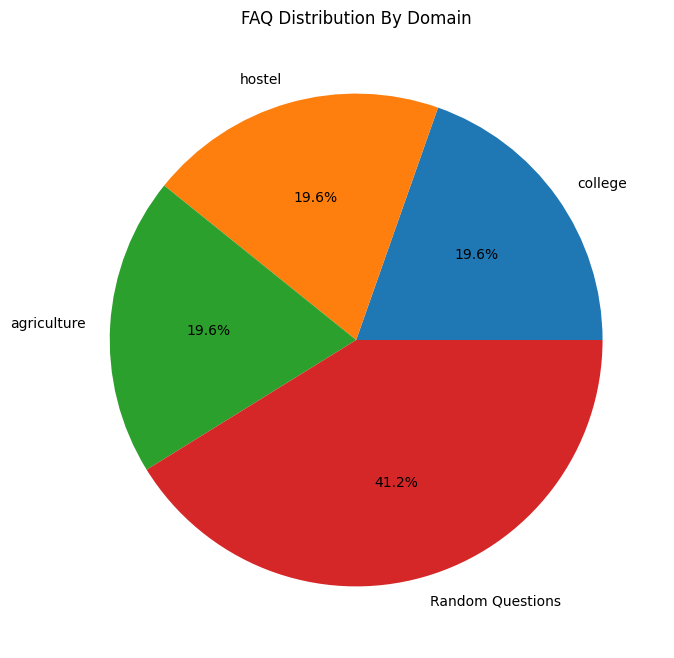

In [4]:
import matplotlib.pyplot as plt

# Count FAQs dynamically from faq_domains
domains = []
faq_counts = []

for domain, questions in faq_domains.items():

    domains.append(domain)

    faq_counts.append(len(questions))

# Create Pie Chart
plt.figure(figsize=(8,8))

plt.pie(
    faq_counts,
    labels=domains,
    autopct='%1.1f%%'
)

# Title
plt.title("FAQ Distribution By Domain")

# Show Visualization
plt.show()

In [5]:
print(Fore.CYAN + "Loading AI Model..." + Style.RESET_ALL)

model = SentenceTransformer('paraphrase-MiniLM-L3-v2')

print(Fore.GREEN + "Model Loaded Successfully" + Style.RESET_ALL)

Loading AI Model...


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.83k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

... (5 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Model Loaded Successfully


In [6]:
print("\nAvailable Domains")
print("1. college")
print("2. hostel")
print("3. agriculture")
print("4. ecommerce")
print("5. Random ")

selected_domain = input("\nSelect Domain: ").lower()


Available Domains
1. college
2. hostel
3. agriculture
4. ecommerce
5. Random 

Select Domain: 1


In [7]:
if selected_domain == '5':
    domain_key = 'Random Questions'
elif selected_domain == '1':
    domain_key = 'college'
elif selected_domain == '2':
    domain_key = 'hostel'
elif selected_domain == '3':
    domain_key = 'agriculture'
else:
    # Fallback in case of unexpected selected_domain, or if 'ecommerce' was intended
    domain_key = 'Random Questions'

faq_data = pd.DataFrame(faq_domains[domain_key])

faq_questions = faq_data['question'].tolist()
faq_answers = faq_data['answer'].tolist()

In [8]:
print(Fore.YELLOW + "Generating FAQ Embeddings..." + Style.RESET_ALL)

faq_embeddings = model.encode(
    faq_questions,
    convert_to_tensor=True
)

print(Fore.GREEN + "Embeddings Ready" + Style.RESET_ALL)

Generating FAQ Embeddings...
Embeddings Ready


In [9]:
chat_history = []

In [10]:
def get_answer(user_question):

    user_embedding = model.encode(
        user_question,
        convert_to_tensor=True
    )

    similarity_scores = util.cos_sim(
        user_embedding,
        faq_embeddings
    )

    best_match_index = similarity_scores.argmax().item()

    score = similarity_scores[0][best_match_index]

    confidence = round(float(score) * 100, 2)

    if score < 0.45:
        return {
            "answer": "Sorry, I could not understand your question.",
            "confidence": confidence
        }

    return {
        "answer": faq_answers[best_match_index],
        "confidence": confidence
    }

In [11]:
print(Fore.MAGENTA + "\nSmart FAQ AI Agent Started" + Style.RESET_ALL)


Smart FAQ AI Agent Started


In [ ]:
while True:

    question = input(
        Fore.CYAN + "\nAsk Your Question (type exit): " + Style.RESET_ALL
    )

    if question.lower() == 'exit':
        print(Fore.RED + "\nClosing AI Agent..." + Style.RESET_ALL)
        break

    result = get_answer(question)

    timestamp = datetime.now().strftime("%H:%M:%S")

    chat_history.append({
        "time": timestamp,
        "question": question,
        "answer": result['answer'],
        "confidence": result['confidence']
    })

    print(Fore.GREEN + "\nAI Agent:" + Style.RESET_ALL)
    print(result['answer'])

    print(Fore.YELLOW + f"Confidence Score: {result['confidence']}%" + Style.RESET_ALL)


Ask Your Question (type exit): how can i pay fees

AI Agent:
You can pay fees through the student portal.
Confidence Score: 77.95%


In [ ]:
question_labels = []
confidence_scores = []

for i, chat in enumerate(chat_history):

    question_labels.append(f"Q{i+1}")

    confidence_scores.append(chat['confidence'])

plt.figure(figsize=(12,6))

bars = plt.bar(
    question_labels,
    confidence_scores
)

plt.xlabel("Questions Asked")
plt.ylabel("Confidence Score (%)")

plt.title("Smart FAQ AI Agent Performance Dashboard")

plt.ylim(0,100)

plt.grid(True)

# Show score on bars
for bar in bars:

    yval = bar.get_height()

    plt.text(
        bar.get_x() + 0.2,
        yval + 1,
        str(yval) + "%"
    )

plt.show()

In [ ]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

text = """
college hostel agriculture ecommerce
library fees refund crops farming
wifi hostel order payment delivery
"""

wordcloud = WordCloud(
    width=800,
    height=400,
    background_color='white'
).generate(text)

plt.figure(figsize=(10,5))

plt.imshow(wordcloud)

plt.axis("off")

plt.title("FAQ Keywords Word Cloud")

plt.show()

In [ ]:
import matplotlib.pyplot as plt

domains = ['College', 'Hostel', 'Agriculture', 'Ecommerce','Random Questions']
faq_counts = [20, 15, 18, 12, 15]

plt.figure(figsize=(7,7))

plt.pie(
    faq_counts,
    labels=domains,
    autopct='%1.1f%%'
)

plt.title("FAQ Distribution By Domain")

plt.show()

In [ ]:
import matplotlib.pyplot as plt

questions = [
    'Library',
    'Hostel',
    'Fees',
    'Refund',
    'Delivery'
]

scores = [92, 85, 76, 64, 48]

plt.figure(figsize=(8,5))

plt.bar(questions, scores)

plt.xlabel("Questions")
plt.ylabel("Confidence Score")
plt.title("FAQ Confidence Scores")

plt.show()

In [ ]:
print(Fore.BLUE + "\nChat History" + Style.RESET_ALL)

for chat in chat_history:

    print("\n--------------------------------")
    print("Time:", chat['time'])
    print("Question:", chat['question'])
    print("Answer:", chat['answer'])
    print("Confidence:", str(chat['confidence']) + "%")

In [ ]:
import matplotlib.pyplot as plt

# Extract data from chat history
question_numbers = []
confidence_scores = []

for i, chat in enumerate(chat_history):

    question_numbers.append(i + 1)

    confidence_scores.append(chat['confidence'])

# Create graph
plt.figure(figsize=(10,5))

plt.plot(
    question_numbers,
    confidence_scores,
    marker='o'
)

# Labels
plt.xlabel("Question Number")
plt.ylabel("Confidence Score (%)")

# Title
plt.title("FAQ AI Agent Confidence Analysis")

# Grid
plt.grid(True)

# Show graph
plt.show()